In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/RANJITH BABU/Downloads/DATA SCIENCE/flights.csv.zip")

In [3]:
df.head()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


In [4]:
df.tail()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
336771,336771,2013,9,30,NaN,1455,NaN,NaN,1634,NaN,...,3393,NaN,JFK,DCA,NaN,213,14,55,2013-09-30 14:00:00,Endeavor Air Inc.
336772,336772,2013,9,30,NaN,2200,NaN,NaN,2312,NaN,...,3525,NaN,LGA,SYR,NaN,198,22,0,2013-09-30 22:00:00,Endeavor Air Inc.
336773,336773,2013,9,30,NaN,1210,NaN,NaN,1330,NaN,...,3461,N535MQ,LGA,BNA,NaN,764,12,10,2013-09-30 12:00:00,Envoy Air
336774,336774,2013,9,30,NaN,1159,NaN,NaN,1344,NaN,...,3572,N511MQ,LGA,CLE,NaN,419,11,59,2013-09-30 11:00:00,Envoy Air
336775,336775,2013,9,30,NaN,840,NaN,NaN,1020,NaN,...,3531,N839MQ,LGA,RDU,NaN,431,8,40,2013-09-30 08:00:00,Envoy Air


In [5]:

print("Dataset Shape:", df.shape)

print("Column Names:")
print(df.columns)

print("Data Types:")
print(df.dtypes)

Dataset Shape: (336776, 21)
Column Names:
Index(['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'name'],
      dtype='str')
Data Types:
id                  int64
year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier               str
flight              int64
tailnum               str
origin                str
dest                  str
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour             str
name                  str
dtype: object


In [6]:
print(df.isnull().sum())

id                   0
year                 0
month                0
day                  0
dep_time          8255
sched_dep_time       0
dep_delay         8255
arr_time          8713
sched_arr_time       0
arr_delay         9430
carrier              0
flight               0
tailnum           2512
origin               0
dest                 0
air_time          9430
distance             0
hour                 0
minute               0
time_hour            0
name                 0
dtype: int64


In [7]:
print(df.isnull().sum().sum())

46595


In [8]:
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna("Unknown")

print("Missing Values Handled Successfully")

print(df.isnull().sum().sum())

C:\Users\RANJITH BABU\AppData\Local\Temp\ipykernel_1672\3259595975.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


Missing Values Handled Successfully
0


In [9]:
df['time_hour'] = pd.to_datetime(df['time_hour'])

print(df.dtypes)

id                         int64
year                       int64
month                      int64
day                        int64
dep_time                 float64
sched_dep_time             int64
dep_delay                float64
arr_time                 float64
sched_arr_time             int64
arr_delay                float64
carrier                      str
flight                     int64
tailnum                      str
origin                       str
dest                         str
air_time                 float64
distance                   int64
hour                       int64
minute                     int64
time_hour         datetime64[us]
name                         str
dtype: object


In [10]:
cat_cols = ['carrier', 'origin', 'dest', 'name']

print("Categorical Columns:")
print(cat_cols)

print("\nUnique Values:")
for col in cat_cols:
    print(col, ":", df[col].nunique())

Categorical Columns:
['carrier', 'origin', 'dest', 'name']

Unique Values:
carrier : 16
origin : 3
dest : 105
name : 16


In [11]:
encoded_df = pd.get_dummies(
    df,
    columns=['carrier', 'origin', 'dest'],
    dtype=int
)

print("Encoding Completed")

display(encoded_df.head())

Encoding Completed


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,dest_SNA,dest_SRQ,dest_STL,dest_STT,dest_SYR,dest_TPA,dest_TUL,dest_TVC,dest_TYS,dest_XNA
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,0,0,0,0,0,0,0,0,0,0
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,0,0,0,0,0,0,0,0,0,0
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,0,0,0,0,0,0,0,0,0,0
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,0,0,0,0,0,0,0,0,0,0
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
for col in cat_cols:
    print("\nFrequency Distribution of", col)
    print(df[col].value_counts())


Frequency Distribution of carrier
carrier
UA    58665
B6    54635
EV    54173
DL    48110
AA    32729
MQ    26397
US    20536
9E    18460
WN    12275
VX     5162
FL     3260
AS      714
F9      685
YV      601
HA      342
OO       32
Name: count, dtype: int64

Frequency Distribution of origin
origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

Frequency Distribution of dest
dest
ORD    17283
ATL    17215
LAX    16174
BOS    15508
MCO    14082
       ...  
MTJ       15
SBN       10
ANC        8
LEX        1
LGA        1
Name: count, Length: 105, dtype: int64

Frequency Distribution of name
name
United Air Lines Inc.          58665
JetBlue Airways                54635
ExpressJet Airlines Inc.       54173
Delta Air Lines Inc.           48110
American Airlines Inc.         32729
Envoy Air                      26397
US Airways Inc.                20536
Endeavor Air Inc.              18460
Southwest Airlines Co.         12275
Virgin America                  5162
AirT

In [13]:
for col in cat_cols:
    print("\nPercentage Distribution of", col)

    percentage = df[col].value_counts(normalize=True) * 100

    print(percentage.round(2))


Percentage Distribution of carrier
carrier
UA    17.42
B6    16.22
EV    16.09
DL    14.29
AA     9.72
MQ     7.84
US     6.10
9E     5.48
WN     3.64
VX     1.53
FL     0.97
AS     0.21
F9     0.20
YV     0.18
HA     0.10
OO     0.01
Name: proportion, dtype: float64

Percentage Distribution of origin
origin
EWR    35.88
JFK    33.04
LGA    31.08
Name: proportion, dtype: float64

Percentage Distribution of dest
dest
ORD    5.13
ATL    5.11
LAX    4.80
BOS    4.60
MCO    4.18
       ... 
MTJ    0.00
SBN    0.00
ANC    0.00
LEX    0.00
LGA    0.00
Name: proportion, Length: 105, dtype: float64

Percentage Distribution of name
name
United Air Lines Inc.          17.42
JetBlue Airways                16.22
ExpressJet Airlines Inc.       16.09
Delta Air Lines Inc.           14.29
American Airlines Inc.          9.72
Envoy Air                       7.84
US Airways Inc.                 6.10
Endeavor Air Inc.               5.48
Southwest Airlines Co.          3.64
Virgin America                

In [14]:
for col in cat_cols:
    print("\nMost Common Category in", col)

    print(df[col].value_counts().idxmax())


Most Common Category in carrier
UA

Most Common Category in origin
EWR

Most Common Category in dest
ORD

Most Common Category in name
United Air Lines Inc.


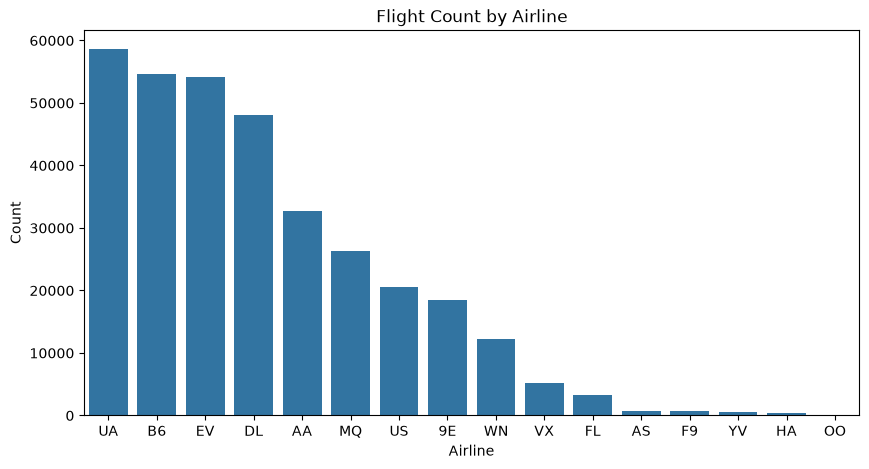

In [15]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='carrier',
              order=df['carrier'].value_counts().index)

plt.title("Flight Count by Airline")
plt.xlabel("Airline")
plt.ylabel("Count")

plt.show()

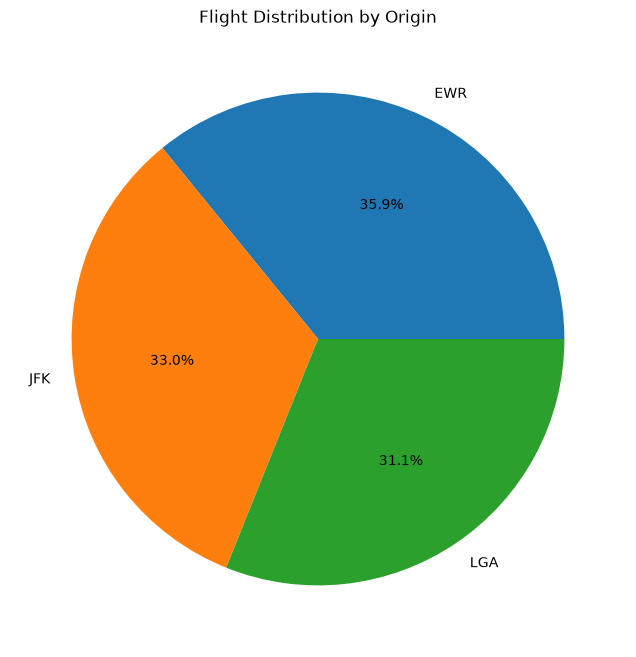

In [16]:
plt.figure(figsize=(8,8))

df['origin'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Flight Distribution by Origin")

plt.ylabel("")

plt.show()

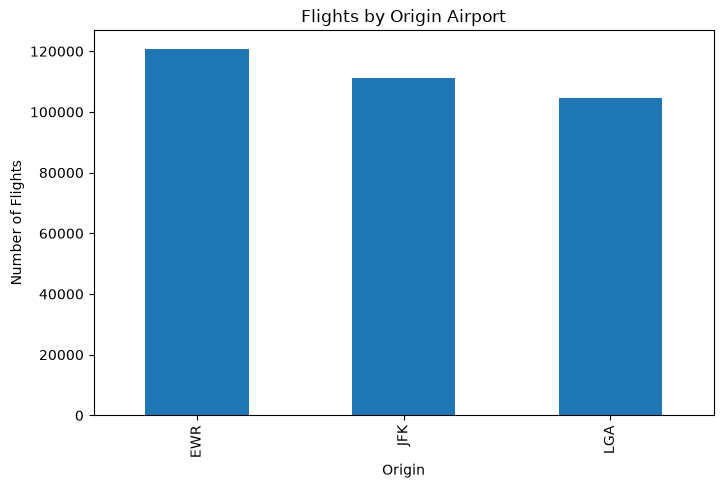

In [17]:
plt.figure(figsize=(8,5))

df['origin'].value_counts().plot(kind='bar')

plt.title("Flights by Origin Airport")
plt.xlabel("Origin")
plt.ylabel("Number of Flights")

plt.show()

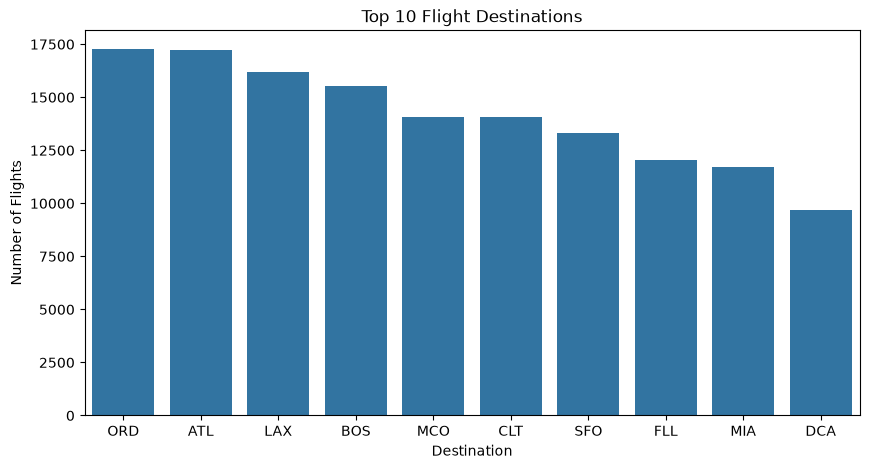

In [18]:
top_dest = df['dest'].value_counts().head(10)

plt.figure(figsize=(10,5))

sns.barplot(x=top_dest.index, y=top_dest.values)

plt.title("Top 10 Flight Destinations")
plt.xlabel("Destination")
plt.ylabel("Number of Flights")

plt.show()

In [19]:
print("FINAL ANALYSIS")

print("Dataset Shape:", df.shape)

print("\nCategorical Analysis:")

for col in cat_cols:

    print("\nColumn:", col)

    print("Total Categories:", df[col].nunique())

    print("Most Common Category:",
          df[col].value_counts().idxmax())

    print("Highest Frequency:",
          df[col].value_counts().max())

print("\nAnalysis Completed Successfully!")

FINAL ANALYSIS
Dataset Shape: (336776, 21)

Categorical Analysis:

Column: carrier
Total Categories: 16
Most Common Category: UA
Highest Frequency: 58665

Column: origin
Total Categories: 3
Most Common Category: EWR
Highest Frequency: 120835

Column: dest
Total Categories: 105
Most Common Category: ORD
Highest Frequency: 17283

Column: name
Total Categories: 16
Most Common Category: United Air Lines Inc.
Highest Frequency: 58665

Analysis Completed Successfully!
